# 07. Strojenie hiperparametrów

**Krok procesu:** 7. Strojenie parametrów, potem bramka 8.

Do tej pory model miał domyślne parametry (MLP 128-64). Teraz szukamy lepszych przy preprocessingu i augmentacji
wybranych przez poprzednie bramki.

**Metoda:** losowe przeszukiwanie (random search), 10 konfiguracji, każda trenowana raz (ziarno 0).
Dwie najlepsze według testu obciążeniowego trenujemy jeszcze z 3 ziarnami i dopiero je przepuszczamy przez bramkę.
Losowe przeszukiwanie zamiast pełnej siatki, bo pełna siatka poniżej to 108 treningów. Przy kosztach energii
(GreenAI) 10 treningów wystarczy, żeby zobaczyć trend.

| Parametr | Wartości |
|---|---|
| `hidden_layer_sizes` | (64,), (128,), (64, 32), (128, 64), (256, 128), (256, 128, 64) |
| `alpha` (regularyzacja L2) | 1e-5, 1e-4, 1e-3 |
| `learning_rate_init` | 3e-4, 1e-3, 3e-3 |
| `batch_size` | 200, 512 |

In [1]:
import sys
sys.path.insert(0, "../src")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import ParameterGrid
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from pipeline import PREPROCESS, augment, gate, load_split, run_experiment, stress_set

FIG = Path("../reports/figures")
GATES = Path("../experiments/gates.json")
LOG = Path("../experiments/log.csv")
sns.set_theme(style="whitegrid")

gates = json.loads(GATES.read_text())
prev = gates["augmentation"]
prev_id, prep_name, copies = prev["experiment_id"], prev["preprocess"], prev["augment_copies"]
prep = PREPROCESS[prep_name]
print("Start od:", prev_id, prep_name, "kopie augmentacji:", copies)

lm_tr, y_tr, _ = load_split("train")
if copies:
    lm_tr, y_tr = augment(lm_tr, y_tr, np.random.default_rng(0), copies=copies)
lm_va, y_va, _ = load_split("val")
X_tr, X_va, X_st = prep(lm_tr), prep(lm_va), prep(stress_set(lm_va))
current = pd.read_csv(LOG).set_index("experiment_id").loc[prev_id].to_dict()

Start od: A1 wrist_scale kopie augmentacji: 1


In [2]:
grid = list(ParameterGrid({"hidden_layer_sizes": [(64,), (128,), (64, 32), (128, 64), (256, 128), (256, 128, 64)],
                           "alpha": [1e-5, 1e-4, 1e-3], "learning_rate_init": [3e-4, 1e-3, 3e-3],
                           "batch_size": [200, 512]}))
picked = [grid[i] for i in np.random.default_rng(42).choice(len(grid), 10, replace=False)]

def make(params):
    return lambda seed: make_pipeline(StandardScaler(), MLPClassifier(**params, early_stopping=True, max_iter=50,
                                                                      random_state=seed))

search = []
for k, params in enumerate(picked, 1):
    exp_id = f"T{k:02d}"
    res, _ = run_experiment(exp_id, "tuning search", make(params), X_tr, y_tr, X_va, y_va, X_st, seeds=(0,),
                            notes={"model": f"MLP {params}", "notes": f"{prep_name}, augmentacja {copies}"})
    search.append({"experiment_id": exp_id, **{k_: str(v) for k_, v in params.items()}, **res})
search = pd.DataFrame(search).set_index("experiment_id")
cols = ["hidden_layer_sizes", "alpha", "learning_rate_init", "batch_size", "val_macro_f1", "val_stress_macro_f1",
        "train_time_s", "co2_g", "model_size_kb", "latency_ms"]
search.sort_values("val_stress_macro_f1", ascending=False)[cols].round(4)

[codecarbon INFO @ 17:26:21] offline tracker init


[codecarbon WARNING @ 17:26:21] Multiple instances of codecarbon are allowed to run at the same time.


/Users/jakub.wi/Documents/semestr7/projekt_WTUM/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


,hidden_layer_sizes,alpha,learning_rate_init,batch_size,val_macro_f1,val_stress_macro_f1,train_time_s,co2_g,model_size_kb,latency_ms
experiment_id,,,,,,,,,,
T04,"(256, 128)",0.0001,0.0003,512,0.9937,0.9911,146.7826,0.3955,533.3467,0.1431
T08,"(128, 64)",1e-05,0.001,200,0.9938,0.9903,88.2747,0.2384,175.3291,0.1368
T06,"(256, 128)",0.001,0.0003,512,0.9932,0.9901,102.9492,0.2769,533.0166,0.1422
T01,"(128, 64)",1e-05,0.0003,200,0.9932,0.9901,53.4671,0.1439,174.9756,0.1375
T09,"(128,)",1e-05,0.0003,512,0.9929,0.9888,71.0794,0.1912,83.3623,0.1348
T10,"(256, 128, 64)",0.001,0.003,200,0.9935,0.9881,145.2582,0.3913,625.5938,0.1454
T03,"(64, 32)",1e-05,0.003,200,0.9935,0.9879,40.4391,0.1088,68.1631,0.1362
T02,"(128,)",0.001,0.003,200,0.9932,0.9876,75.7030,0.2039,83.1426,0.1369
T07,"(64,)",0.001,0.001,200,0.9932,0.9871,51.5634,0.1386,46.2217,0.1336


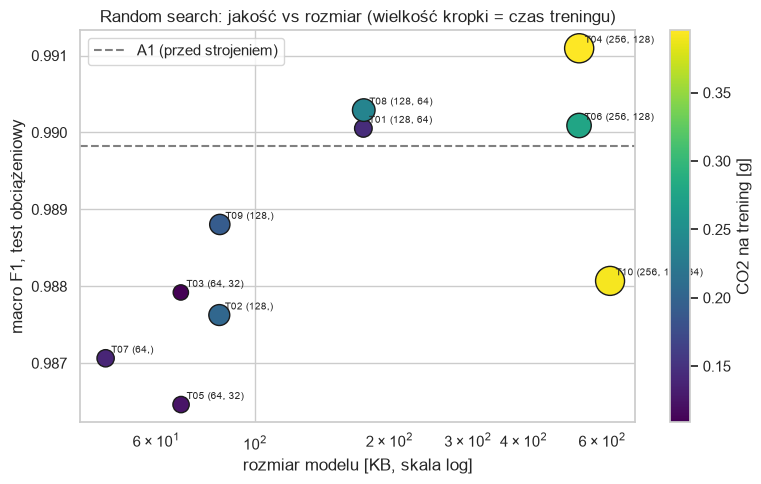

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(search.model_size_kb, search.val_stress_macro_f1, s=search.train_time_s * 3, c=search.co2_g,
                cmap="viridis", edgecolor="k")
for i, r in search.iterrows():
    ax.annotate(f"{i} {r.hidden_layer_sizes}", (r.model_size_kb, r.val_stress_macro_f1), fontsize=7,
                xytext=(4, 4), textcoords="offset points")
ax.axhline(current["val_stress_macro_f1"], ls="--", color="grey", label=f"{prev_id} (przed strojeniem)")
ax.set(xscale="log", xlabel="rozmiar modelu [KB, skala log]", ylabel="macro F1, test obciążeniowy",
       title="Random search: jakość vs rozmiar (wielkość kropki = czas treningu)")
plt.colorbar(sc, label="CO2 na trening [g]"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "tuning_search.png", dpi=150); plt.show()

## Dwie najlepsze konfiguracje z 3 ziarnami i bramka

In [4]:
top = search.sort_values("val_stress_macro_f1", ascending=False).head(2).index
results, decisions = {prev_id: current}, []
best, best_id, best_params = current, prev_id, None
for exp_id in top:
    params = picked[int(exp_id[1:]) - 1]
    final_id = f"{exp_id}x3"
    res, _ = run_experiment(final_id, "tuning", make(params), X_tr, y_tr, X_va, y_va, X_st,
                            notes={"model": f"MLP {params}", "notes": f"{prep_name}, augmentacja {copies}, 3 ziarna"})
    passed, reasons = gate(current, res)
    decisions.append({"eksperyment": final_id, "porównanie z": prev_id, "bramka": "przechodzi" if passed else "odrzucony",
                      "powody": "; ".join(reasons)})
    results[final_id] = res
    if passed and res["val_stress_macro_f1"] > best["val_stress_macro_f1"]:
        best, best_id, best_params = res, final_id, params
pd.DataFrame(decisions)

,eksperyment,porównanie z,bramka,powody
0,T04x3,A1,odrzucony,"stress F1 +0.0007 (próg szumu 0.0011), val F1 ..."
1,T08x3,A1,odrzucony,"stress F1 -0.0002 (próg szumu 0.0013), val F1 ..."


In [5]:
pd.DataFrame(results).T[["val_macro_f1", "val_macro_f1_std", "val_stress_macro_f1", "val_stress_macro_f1_std",
                         "train_time_s", "co2_g", "model_size_kb", "latency_ms"]].astype(float).round(4)

,val_macro_f1,val_macro_f1_std,val_stress_macro_f1,val_stress_macro_f1_std,train_time_s,co2_g,model_size_kb,latency_ms
A1,0.9934,0.0003,0.9898,0.0003,96.8072,0.2607,175.1172,0.1356
T04x3,0.9934,0.0002,0.9905,0.0006,113.7411,0.3059,533.3467,0.1423
T08x3,0.9936,0.0001,0.9896,0.0006,83.6961,0.2254,175.3291,0.1367


In [6]:
tuning_log = pd.read_csv(LOG)
tuning_log = tuning_log[tuning_log.process_step.isin(["tuning search", "tuning"])]
total = (tuning_log.co2_g * tuning_log.seeds).sum(), (tuning_log.energy_kwh * tuning_log.seeds).sum()
print(f"Całe strojenie: {int(tuning_log.seeds.sum())} treningów, {total[1] * 1000:.1f} Wh, {total[0]:.2f} g CO2")

Całe strojenie: 16 treningów, 5.7 Wh, 3.81 g CO2


In [7]:
if best_params is None:
    best_params = {"hidden_layer_sizes": (128, 64), "alpha": 1e-4, "learning_rate_init": 1e-3, "batch_size": 200}
gates["tuning"] = {"experiment_id": best_id, "preprocess": prep_name, "augment_copies": copies,
                   "params": {k: list(v) if isinstance(v, tuple) else v for k, v in best_params.items()}}
GATES.write_text(json.dumps(gates, indent=2, ensure_ascii=False))
print("Model końcowy:", best_id, best_params)

Model końcowy: A1 {'hidden_layer_sizes': (128, 64), 'alpha': 0.0001, 'learning_rate_init': 0.001, 'batch_size': 200}


## Wnioski

- **Żadna konfiguracja nie przeszła bramki. Zostaje A1 z domyślnymi parametrami.** Dwie najlepsze z wyszukiwania
  po 3 ziarnach dały +0.0007 (T04, sieć 256-128) i -0.0002 (T08) na teście obciążeniowym. Oba wyniki mieszczą się
  w szumie (próg około 0.001). T04 jest dodatkowo 3 razy większy (533 KB zamiast 175 KB), więc odpadłby też
  na koszcie predykcji.
- **Domyślne parametry były już na płaskowyżu.** 8 z 10 konfiguracji ma test obciążeniowy między 0.987 a 0.991,
  a val między 0.9929 a 0.9938. Przy 1.2 mln przykładów i 42 cechach ten MLP nie jest ograniczony parametrami.
  Ograniczeniem są dane (25 póz z HaGRID).
- **Mniejsze sieci są prawie tak samo dobre.** Sieć (64,) ma 46 KB i 0.987 na teście obciążeniowym, czyli 0.003
  mniej niż model końcowy przy 4 razy mniejszym rozmiarze. Nasza bramka wymaga wzrostu jakości, więc jej nie
  wybiera. Gdyby telefon był bardzo słaby, to byłby rozsądny kompromis.
- **Strojenie to najdroższy krok procesu pod względem GreenAI.** 16 treningów, 5.7 Wh i 3.81 g CO2. To prawie
  połowa emisji całego procesu (7.92 g, patrz `08_final_model.ipynb`), a nie dało żadnego zysku. Wniosek na
  przyszłość: najpierw sprawdzić, czy model jest ograniczony parametrami, a dopiero potem stroić.
- Część konfiguracji z `learning_rate_init` 3e-4 doszła do limitu 50 epok (ostrzeżenie `ConvergenceWarning`).
  Przy takich wynikach dłuższy trening raczej nic by nie zmienił, a kosztowałby więcej energii.